In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
df=pd.read_csv("emergency_service.csv")
df

,Timestamp,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,Road_Type,Emergency_Level,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Response_Time
0,01/01/2018 00:00,Low,Cardiac Arrest,Suburban,High,Clear,Available,91,8.89,1,Unavailable,Highway,Major,43.549849,90.030756,Severe,AI,20.870220
1,01/01/2018 00:10,Low,Other,Urban,Moderate,Clear,Available,28,28.10,2,Unavailable,Highway,Critical,30.687975,88.255008,Moderate,Human,24.486195
2,01/01/2018 00:20,Medium,Cardiac Arrest,Suburban,High,Rainy,Available,83,40.43,1,Unavailable,Unpaved Road,Minor,44.456331,97.719622,No Impact,Human,18.760740
3,01/01/2018 00:30,Low,Accident,Urban,Moderate,Clear,Available,31,18.97,3,Available,Highway,Minor,35.879968,60.234672,No Impact,Human,18.169534
4,01/01/2018 00:40,Low,Cardiac Arrest,Urban,Moderate,Stormy,Available,52,16.31,3,Available,Highway,Minor,26.369383,71.083564,Moderate,Human,5.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368060,30/12/2024 23:20,Medium,Cardiac Arrest,Rural,Low,Clear,Available,85,24.11,3,Unavailable,Highway,Minor,52.560965,52.118376,Moderate,Human,12.465708
368061,30/12/2024 23:30,High,Accident,Suburban,Low,Clear,Available,45,43.26,1,Unavailable,Highway,Minor,42.738073,71.485832,Moderate,Human,11.006577
368062,30/12/2024 23:40,Low,Fire,Urban,Moderate,Rainy,Unavailable,97,42.13,1,Available,Unpaved Road,Minor,43.578888,51.960692,Moderate,Human,16.782428
368063,30/12/2024 23:50,Medium,Accident,Urban,Moderate,Clear,Available,37,39.57,2,Unavailable,Highway,Major,30.379377,87.275648,No Impact,Human,14.063774


In [2]:
df['Timestamp']=pd.to_datetime(df['Timestamp'],format='%d/%m/%Y %H:%M')

In [3]:
df_subset=df[(df['Timestamp'] >= '2022-01-01') & (df['Timestamp'] <='2024-12-31')]

In [4]:
df_subset.dtypes

Timestamp                  datetime64[ns]
Incident_Severity                  object
Incident_Type                      object
Region_Type                        object
Traffic_Congestion                 object
Weather_Condition                  object
Ambulance_Availability             object
Hospital_Capacity                   int64
Distance_to_Incident              float64
Number_of_Injuries                  int64
Specialist_Availability            object
Road_Type                          object
Emergency_Level                    object
Ambulance_Speed                   float64
Fuel_Level                        float64
Weather_Impact                     object
Dispatch_Coordinator               object
Response_Time                     float64
dtype: object

In [5]:
df_subset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 157681 entries, 210384 to 368064
Data columns (total 18 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   Timestamp                157681 non-null  datetime64[ns]
 1   Incident_Severity        157681 non-null  object        
 2   Incident_Type            157681 non-null  object        
 3   Region_Type              157681 non-null  object        
 4   Traffic_Congestion       157681 non-null  object        
 5   Weather_Condition        157681 non-null  object        
 6   Ambulance_Availability   157681 non-null  object        
 7   Hospital_Capacity        157681 non-null  int64         
 8   Distance_to_Incident     157681 non-null  float64       
 9   Number_of_Injuries       157681 non-null  int64         
 10  Specialist_Availability  157681 non-null  object        
 11  Road_Type                157681 non-null  object        
 12  Emergency_Level 

In [6]:
#Activity 2: Predicting Emergency Response Time 
# 1 selcetion methods 
# depend on the slides, i chose 2 selction methods which are : 
# filter method --> select K best
# Embedding methods --> random forest 

#first, im going to prepare the data for the feature selection methods 

df_model=df_subset.copy()

# first, i`m going to work on datetime
#since the modle cant read it as it is , im going to devide it to parts 
df_model['Year']=df_model['Timestamp'].dt.year
df_model['Month']=df_model['Timestamp'].dt.month
df_model['Day']=df_model['Timestamp'].dt.day
df_model['Hour']=df_model['Timestamp'].dt.hour
df_model['DayOfWeek']=df_model['Timestamp'].dt.dayofweek # 0 means monday,6 means Sunday

#drop the original Timestamp column 
df_model=df_model.drop(columns=['Timestamp'])
df_model

,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,...,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Response_Time,Year,Month,Day,Hour,DayOfWeek
210384,Medium,Accident,Urban,Low,Clear,Available,75,9.80,1,Unavailable,...,49.424852,82.031051,Moderate,AI,13.510247,2022,1,1,0,5
210385,Low,Fire,Urban,Low,Clear,Available,85,39.16,1,Available,...,34.188224,93.735875,No Impact,Human,16.654818,2022,1,1,0,5
210386,Low,Cardiac Arrest,Urban,High,Clear,Available,26,10.43,1,Unavailable,...,46.330663,100.000000,No Impact,Human,17.802266,2022,1,1,0,5
210387,Low,Accident,Urban,Moderate,Rainy,Available,60,39.85,1,Unavailable,...,41.498126,88.131774,No Impact,Human,5.000000,2022,1,1,0,5
210388,Low,Accident,Rural,Low,Clear,Available,93,38.59,1,Unavailable,...,32.398124,73.247545,Moderate,Human,15.354402,2022,1,1,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368060,Medium,Cardiac Arrest,Rural,Low,Clear,Available,85,24.11,3,Unavailable,...,52.560965,52.118376,Moderate,Human,12.465708,2024,12,30,23,0
368061,High,Accident,Suburban,Low,Clear,Available,45,43.26,1,Unavailable,...,42.738073,71.485832,Moderate,Human,11.006577,2024,12,30,23,0
368062,Low,Fire,Urban,Moderate,Rainy,Unavailable,97,42.13,1,Available,...,43.578888,51.960692,Moderate,Human,16.782428,2024,12,30,23,0
368063,Medium,Accident,Urban,Moderate,Clear,Available,37,39.57,2,Unavailable,...,30.379377,87.275648,No Impact,Human,14.063774,2024,12,30,23,0


In [7]:
#now time for defineing the target variable 
target="Response_Time"

#define x and y for modeling
x=df_model.drop(columns=[target])
y=df_model[target]

#see the results
print("x shape: ",x.shape)
print("y shape: ",y.shape)


x shape:  (157681, 21)
y shape:  (157681,)


In [8]:
df_model.head()

,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,...,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Response_Time,Year,Month,Day,Hour,DayOfWeek
210384,Medium,Accident,Urban,Low,Clear,Available,75,9.80,1,Unavailable,...,49.424852,82.031051,Moderate,AI,13.510247,2022,1,1,0,5
210385,Low,Fire,Urban,Low,Clear,Available,85,39.16,1,Available,...,34.188224,93.735875,No Impact,Human,16.654818,2022,1,1,0,5
210386,Low,Cardiac Arrest,Urban,High,Clear,Available,26,10.43,1,Unavailable,...,46.330663,100.000000,No Impact,Human,17.802266,2022,1,1,0,5
210387,Low,Accident,Urban,Moderate,Rainy,Available,60,39.85,1,Unavailable,...,41.498126,88.131774,No Impact,Human,5.000000,2022,1,1,0,5
210388,Low,Accident,Rural,Low,Clear,Available,93,38.59,1,Unavailable,...,32.398124,73.247545,Moderate,Human,15.354402,2022,1,1,0,5


In [9]:
df_model.dtypes

Incident_Severity           object
Incident_Type               object
Region_Type                 object
Traffic_Congestion          object
Weather_Condition           object
Ambulance_Availability      object
Hospital_Capacity            int64
Distance_to_Incident       float64
Number_of_Injuries           int64
Specialist_Availability     object
Road_Type                   object
Emergency_Level             object
Ambulance_Speed            float64
Fuel_Level                 float64
Weather_Impact              object
Dispatch_Coordinator        object
Response_Time              float64
Year                         int32
Month                        int32
Day                          int32
Hour                         int32
DayOfWeek                    int32
dtype: object

In [10]:
# After identifying x and y , time for the encoding. 
#first, i want to knoe the catagogical fearures and choose the best encing type for 
#each one. 
#so that: 
catarogical_cols=x.select_dtypes(include=['object']).columns
print("Catarogical columns: ")
print(catarogical_cols)
print("number of catarogical cols: ",len(catarogical_cols))

Catarogical columns: 
Index(['Incident_Severity', 'Incident_Type', 'Region_Type',
       'Traffic_Congestion', 'Weather_Condition', 'Ambulance_Availability',
       'Specialist_Availability', 'Road_Type', 'Emergency_Level',
       'Weather_Impact', 'Dispatch_Coordinator'],
      dtype='object')
number of catarogical cols:  11


In [11]:
df_model.head()

,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,...,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Response_Time,Year,Month,Day,Hour,DayOfWeek
210384,Medium,Accident,Urban,Low,Clear,Available,75,9.80,1,Unavailable,...,49.424852,82.031051,Moderate,AI,13.510247,2022,1,1,0,5
210385,Low,Fire,Urban,Low,Clear,Available,85,39.16,1,Available,...,34.188224,93.735875,No Impact,Human,16.654818,2022,1,1,0,5
210386,Low,Cardiac Arrest,Urban,High,Clear,Available,26,10.43,1,Unavailable,...,46.330663,100.000000,No Impact,Human,17.802266,2022,1,1,0,5
210387,Low,Accident,Urban,Moderate,Rainy,Available,60,39.85,1,Unavailable,...,41.498126,88.131774,No Impact,Human,5.000000,2022,1,1,0,5
210388,Low,Accident,Rural,Low,Clear,Available,93,38.59,1,Unavailable,...,32.398124,73.247545,Moderate,Human,15.354402,2022,1,1,0,5


In [12]:
df_model["Emergency_Level"].unique()

array(['Minor', 'Major', 'Critical'], dtype=object)

In [13]:
df_model["Incident_Severity"].unique()

array(['Medium', 'Low', 'High'], dtype=object)

In [14]:
df_model["Traffic_Congestion"].unique()

array(['Low', 'High', 'Moderate'], dtype=object)

In [15]:
# i read the data, depends on the type of the object data, i decided:
# Incident_Severity, Traffic_Congestion	,Emergency_Level ordinal encoding because 
# they have an order (low, medium, high ), (['Minor', 'Major', 'Critical'])
# label encoding : 

x_encoded=x.copy()

#ordinal encoding for ordered colmuns 
incident_ordinal_cols={
    "Low":0,
    "Medium":1,
    "High":2
}
x_encoded['Incident_Severity']= x_encoded['Incident_Severity'].map(incident_ordinal_cols)

traffic_ordinal_cols={
    "Low":0,
    "Moderate":1,
    "High":2
}
x_encoded['Traffic_Congestion']= x_encoded['Traffic_Congestion'].map(traffic_ordinal_cols)
x_encoded

,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,...,Emergency_Level,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Year,Month,Day,Hour,DayOfWeek
210384,1,Accident,Urban,0,Clear,Available,75,9.80,1,Unavailable,...,Minor,49.424852,82.031051,Moderate,AI,2022,1,1,0,5
210385,0,Fire,Urban,0,Clear,Available,85,39.16,1,Available,...,Minor,34.188224,93.735875,No Impact,Human,2022,1,1,0,5
210386,0,Cardiac Arrest,Urban,2,Clear,Available,26,10.43,1,Unavailable,...,Minor,46.330663,100.000000,No Impact,Human,2022,1,1,0,5
210387,0,Accident,Urban,1,Rainy,Available,60,39.85,1,Unavailable,...,Minor,41.498126,88.131774,No Impact,Human,2022,1,1,0,5
210388,0,Accident,Rural,0,Clear,Available,93,38.59,1,Unavailable,...,Minor,32.398124,73.247545,Moderate,Human,2022,1,1,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368060,1,Cardiac Arrest,Rural,0,Clear,Available,85,24.11,3,Unavailable,...,Minor,52.560965,52.118376,Moderate,Human,2024,12,30,23,0
368061,2,Accident,Suburban,0,Clear,Available,45,43.26,1,Unavailable,...,Minor,42.738073,71.485832,Moderate,Human,2024,12,30,23,0
368062,0,Fire,Urban,1,Rainy,Unavailable,97,42.13,1,Available,...,Minor,43.578888,51.960692,Moderate,Human,2024,12,30,23,0
368063,1,Accident,Urban,1,Clear,Available,37,39.57,2,Unavailable,...,Major,30.379377,87.275648,No Impact,Human,2024,12,30,23,0


In [16]:
Emg_oreder_col={
    "Minor": 0 ,
    "Major" :1 ,
    "Critical":2
}
x_encoded['Emergency_Level']= x_encoded['Emergency_Level'].map(Emg_oreder_col)
x_encoded

,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,...,Emergency_Level,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Year,Month,Day,Hour,DayOfWeek
210384,1,Accident,Urban,0,Clear,Available,75,9.80,1,Unavailable,...,0,49.424852,82.031051,Moderate,AI,2022,1,1,0,5
210385,0,Fire,Urban,0,Clear,Available,85,39.16,1,Available,...,0,34.188224,93.735875,No Impact,Human,2022,1,1,0,5
210386,0,Cardiac Arrest,Urban,2,Clear,Available,26,10.43,1,Unavailable,...,0,46.330663,100.000000,No Impact,Human,2022,1,1,0,5
210387,0,Accident,Urban,1,Rainy,Available,60,39.85,1,Unavailable,...,0,41.498126,88.131774,No Impact,Human,2022,1,1,0,5
210388,0,Accident,Rural,0,Clear,Available,93,38.59,1,Unavailable,...,0,32.398124,73.247545,Moderate,Human,2022,1,1,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368060,1,Cardiac Arrest,Rural,0,Clear,Available,85,24.11,3,Unavailable,...,0,52.560965,52.118376,Moderate,Human,2024,12,30,23,0
368061,2,Accident,Suburban,0,Clear,Available,45,43.26,1,Unavailable,...,0,42.738073,71.485832,Moderate,Human,2024,12,30,23,0
368062,0,Fire,Urban,1,Rainy,Unavailable,97,42.13,1,Available,...,0,43.578888,51.960692,Moderate,Human,2024,12,30,23,0
368063,1,Accident,Urban,1,Clear,Available,37,39.57,2,Unavailable,...,1,30.379377,87.275648,No Impact,Human,2024,12,30,23,0


In [17]:
print(catarogical_cols)

Index(['Incident_Severity', 'Incident_Type', 'Region_Type',
       'Traffic_Congestion', 'Weather_Condition', 'Ambulance_Availability',
       'Specialist_Availability', 'Road_Type', 'Emergency_Level',
       'Weather_Impact', 'Dispatch_Coordinator'],
      dtype='object')


In [18]:
df_model["Incident_Type"].unique() #doesn`t hava an order, one hot

array(['Accident', 'Fire', 'Cardiac Arrest', 'Other'], dtype=object)

In [19]:
df_model["Region_Type"].unique() #doesn`t hava an order, one hot

array(['Urban', 'Rural', 'Suburban'], dtype=object)

In [20]:
df_model["Ambulance_Availability"].unique()

array(['Available', 'Unavailable'], dtype=object)

In [21]:
df_model["Weather_Condition"].unique()

array(['Clear', 'Rainy', 'Stormy'], dtype=object)

In [22]:
#Specialist_Availability
df_model["Specialist_Availability"].unique()

array(['Unavailable', 'Available'], dtype=object)

In [23]:
df_model["Road_Type"].unique()

array(['Highway', 'Local Road', 'Unpaved Road'], dtype=object)

In [24]:
df_model["Dispatch_Coordinator"].unique()

array(['AI', 'Human'], dtype=object)

In [25]:
df_model["Weather_Impact"].unique()

array(['Moderate', 'No Impact', 'Severe'], dtype=object)

In [26]:
#descovered that Weather_Impact is an ordinal encoding
weather_mapping={
    "No Impact": 0 ,
    "Moderate" : 1,
    "Severe" : 2

}
x_encoded["Weather_Impact"]=x_encoded["Weather_Impact"].map(weather_mapping)


availability_mapping = {
    'Unavailable': 0,
    'Available': 1
}
x_encoded["Specialist_Availability"]=x_encoded["Specialist_Availability"].map(availability_mapping)
x_encoded["Ambulance_Availability"]=x_encoded["Ambulance_Availability"].map(availability_mapping)

In [27]:
#one hot encoding (no order)
one_hot_cols = [ 'Incident_Type', 'Region_Type', 'Weather_Condition', 'Road_Type',
    'Dispatch_Coordinator' ]
x_encoded=pd.get_dummies(x_encoded,columns=one_hot_cols,drop_first=True,dtype=int)

print("x shape before encoding:", x.shape)
print("x shape after encoding:", x_encoded.shape)

x_encoded.head()

x shape before encoding: (157681, 21)
x shape after encoding: (157681, 26)


,Incident_Severity,Traffic_Congestion,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,Emergency_Level,Ambulance_Speed,Fuel_Level,...,Incident_Type_Cardiac Arrest,Incident_Type_Fire,Incident_Type_Other,Region_Type_Suburban,Region_Type_Urban,Weather_Condition_Rainy,Weather_Condition_Stormy,Road_Type_Local Road,Road_Type_Unpaved Road,Dispatch_Coordinator_Human
210384,1,0,1,75,9.80,1,0,0,49.424852,82.031051,...,0,0,0,0,1,0,0,0,0,0
210385,0,0,1,85,39.16,1,1,0,34.188224,93.735875,...,0,1,0,0,1,0,0,0,0,1
210386,0,2,1,26,10.43,1,0,0,46.330663,100.000000,...,1,0,0,0,1,0,0,1,0,1
210387,0,1,1,60,39.85,1,0,0,41.498126,88.131774,...,0,0,0,0,1,1,0,0,0,1
210388,0,0,1,93,38.59,1,0,0,32.398124,73.247545,...,0,0,0,0,0,0,0,0,0,1


In [28]:
x_encoded.select_dtypes(include='object').columns

Index([], dtype='object')

In [29]:
x_encoded.isnull().sum()

Incident_Severity               0
Traffic_Congestion              0
Ambulance_Availability          0
Hospital_Capacity               0
Distance_to_Incident            0
Number_of_Injuries              0
Specialist_Availability         0
Emergency_Level                 0
Ambulance_Speed                 0
Fuel_Level                      0
Weather_Impact                  0
Year                            0
Month                           0
Day                             0
Hour                            0
DayOfWeek                       0
Incident_Type_Cardiac Arrest    0
Incident_Type_Fire              0
Incident_Type_Other             0
Region_Type_Suburban            0
Region_Type_Urban               0
Weather_Condition_Rainy         0
Weather_Condition_Stormy        0
Road_Type_Local Road            0
Road_Type_Unpaved Road          0
Dispatch_Coordinator_Human      0
dtype: int64

In [30]:
#select K best method 
from sklearn.feature_selection import SelectKBest,f_regression
#apply K best feature selection
selector=SelectKBest(score_func=f_regression, k=10) # f_regression :because we are usnig the regression 

x_kbest= selector.fit_transform(x_encoded,y)

#get selected festure names 
selected_features_kbest=x_encoded.columns[selector.get_support()]

print("Selected features using SelectKBest: ")
print(selected_features_kbest)

print("Shape before SelectKBest: ",x_encoded.shape)
print("Shape After SelectKBest: ",x_kbest.shape)
#choose the best k (oral)

Selected features using SelectKBest: 
Index(['Traffic_Congestion', 'Ambulance_Availability', 'Distance_to_Incident',
       'Specialist_Availability', 'Day', 'Incident_Type_Other',
       'Region_Type_Suburban', 'Weather_Condition_Stormy',
       'Road_Type_Unpaved Road', 'Dispatch_Coordinator_Human'],
      dtype='object')
Shape before SelectKBest:  (157681, 26)
Shape After SelectKBest:  (157681, 10)


In [31]:
#now create dataframe for select k best scores 
kbest_scores=pd.DataFrame({
    'Feature':x_encoded.columns,
    'Score':selector.scores_
})
#Sort feature by scores from highest to lowest 
kbest_scores=kbest_scores.sort_values(by='Score',ascending=False)
kbest_scores.head(10)

,Feature,Score
22,Weather_Condition_Stormy,4.494318
19,Region_Type_Suburban,4.063203
18,Incident_Type_Other,4.007528
2,Ambulance_Availability,3.608481
6,Specialist_Availability,2.914333
24,Road_Type_Unpaved Road,2.791830
4,Distance_to_Incident,2.367884
25,Dispatch_Coordinator_Human,2.047480
1,Traffic_Congestion,1.395510
13,Day,1.008918


## Insight:

SelectKBest was applied using f_regression because the target variable, Response_Time, is continuous. This method ranked the features based on their statistical relationship with response time.

The selected features included Traffic_Congestion, Ambulance_Availability, Distance_to_Incident, Specialist_Availability, Day, Incident_Type_Other, Region_Type_Suburban, Weather_Condition_Stormy, Road_Type_Unpaved Road, and Dispatch_Coordinator_Human.

Based on the scores, Weather_Condition_Stormy had the highest score among the selected features. However, this does not mean it strongly affects response time; it only means that it ranked highest according to this feature selection method.



In [32]:
# the next feature slection is Embedded feature selection 
# SelectFromModel random forest selection 
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel

randomForest_model = RandomForestRegressor(
    n_estimators=50, # number of trees inside the random forest 
    random_state=42,
    n_jobs=-1
)

#select fearutes based on random forest impoertance
selectFromMod = SelectFromModel(
    estimator=randomForest_model,
    threshold='median'
)
x_selectFromMod = selectFromMod.fit_transform(x_encoded,y)

#get selected feature names 
selected_features_selectFromMod = x_encoded.columns[selectFromMod.get_support()]

print("Selected features using selectFromModle: ")
print(selected_features_selectFromMod)

print("\n")
print("Shape before selectFromModle: ",x_encoded.shape)
print("Shape after selectFromModle: ",x_selectFromMod.shape)

Selected features using selectFromModle: 
Index(['Incident_Severity', 'Traffic_Congestion', 'Hospital_Capacity',
       'Distance_to_Incident', 'Number_of_Injuries', 'Emergency_Level',
       'Ambulance_Speed', 'Fuel_Level', 'Year', 'Month', 'Day', 'Hour',
       'DayOfWeek'],
      dtype='object')


Shape before selectFromModle:  (157681, 26)
Shape after selectFromModle:  (157681, 13)


In [33]:
randomForest_importance=pd.DataFrame({
    'Feature': x_encoded.columns,
    'Impoertance': selectFromMod.estimator_.feature_importances_
})
#sort by importance
randomForest_importance = randomForest_importance.sort_values(by='Impoertance',ascending=False)

randomForest_importance.head(10)

,Feature,Impoertance
8,Ambulance_Speed,0.135319
9,Fuel_Level,0.133469
4,Distance_to_Incident,0.133303
3,Hospital_Capacity,0.102673
13,Day,0.080588
14,Hour,0.075705
12,Month,0.060252
15,DayOfWeek,0.046230
11,Year,0.023879
5,Number_of_Injuries,0.021902


In [34]:
selected_features_selectFromMod=selected_features_selectFromMod.tolist()
x_selectFromMod_df=x_encoded[selected_features_selectFromMod]
print("shpae after selecting features: ",x_selectFromMod_df.shape)
# this code creats new list , and stores the values from selectKmodels in it 
# the purpose is to use it for the prediction ,and minimize the number of features taken 
#to increase the accuracy 

shpae after selecting features:  (157681, 13)


In [35]:
# SelectFromModel was used for feature selection because KMeans is a clustering method,
#not suitable for this regression prediction task.
#for prediction
from sklearn.model_selection import train_test_split

#split the selected feaures to traiing and testing data
X_train, X_test,y_train,y_test= train_test_split(x_selectFromMod_df,y,test_size=0.2,random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (126144, 13)
X_test shape: (31537, 13)
y_train shape: (126144,)
y_test shape: (31537,)


In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## KNN

In [38]:
# KNN Regression Model, first prediction model 
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
# KNN depends on distance, so we scale the data first
scaler = StandardScaler()
# Fit scaler on training data only
X_train_scaled = scaler.fit_transform(X_train)
# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)


In [39]:
# Choose the best K value using MAE
k_values = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
knn_results = []
for k in k_values:
    knn_model = KNeighborsRegressor(n_neighbors=k)
    knn_model.fit(X_train_scaled, y_train)

    y_pred = knn_model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)

    knn_results.append([k, mae])

In [42]:
knn_results_df = pd.DataFrame(knn_results, columns=['K Value', 'MAE'])
print(knn_results_df)
# the result, best k = 10 least MAE 

   K Value       MAE
0        1  5.555777
1        2  4.807619
2        3  4.543039
3        4  4.398411
4        5  4.309224
5        6  4.253398
6        7  4.206761
7        8  4.171183
8        9  4.148449
9       10  4.127594
Best K: 10


In [43]:
# Create final KNN model using the best K value
knn_model = KNeighborsRegressor(n_neighbors=10)
# K = 10 was selected because it gave the lowest MAE.
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)

In [44]:
# Evaluate KNN model
MAE_knn = mean_absolute_error(y_test, y_pred_knn)
MSE_knn = mean_squared_error(y_test, y_pred_knn)
RMSE_knn = np.sqrt(MSE_knn)
R2_knn = r2_score(y_test, y_pred_knn)
# all the results are in minutes : MAE(minutes) ,and so on on all the results 
print("KNN Regression Results:")
print("MAE:", MAE_knn)
print("MSE:", MSE_knn)
print("RMSE:", RMSE_knn)
print("R2 Score:", R2_knn)

KNN Regression Results:
MAE: 4.127594290556207
MSE: 26.321172894416634
RMSE: 5.130416444540992
R2 Score: -0.10017913432020764


In [45]:
#second, we are going to start in linear regression 
# pridective models: 
#1-create the model
linear_model=LinearRegression()

#2-train the model 
linear_model.fit(X_train,y_train)

#3-make_predictions
y_pred_linear=linear_model.predict(X_test)

In [46]:
#evaluate the model
MAE_linear= mean_absolute_error(y_test,y_pred_linear)
MSE_linear = mean_squared_error(y_test,y_pred_linear)
RMSE_linear = np.sqrt(MSE_linear)
R2_linear=r2_score(y_test,y_pred_linear)

#print the results
# all the results are in minutes : MAE(minutes) ,and so on on all the results 
print("Linear Regression Results:")
print("MAE:", MAE_linear)
print("MSE:", MSE_linear)
print("RMSE:", RMSE_linear)
print("R2 Score:", R2_linear)

Linear Regression Results:
MAE: 3.9417497878876055
MSE: 23.93075268766503
RMSE: 4.891906855988269
R2 Score: -0.0002637375301439704


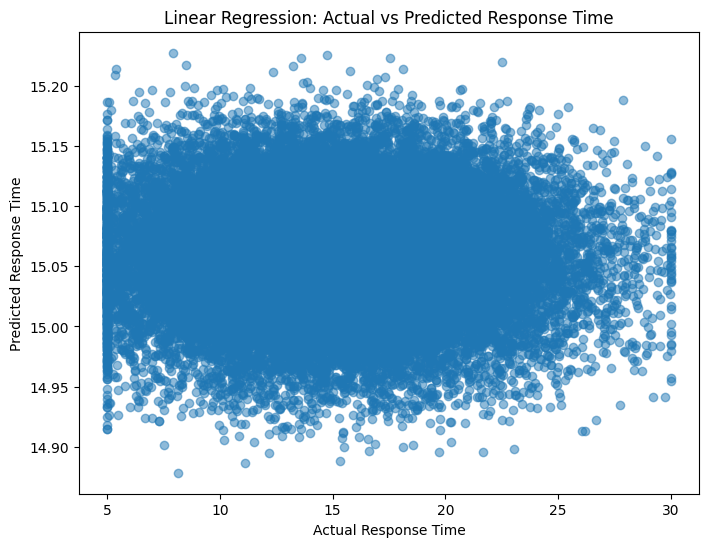

In [47]:
#for more understaning , i want to visualize it 
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_linear, alpha=0.5)

plt.xlabel("Actual Response Time")
plt.ylabel("Predicted Response Time")
plt.title("Linear Regression: Actual vs Predicted Response Time")

plt.show()


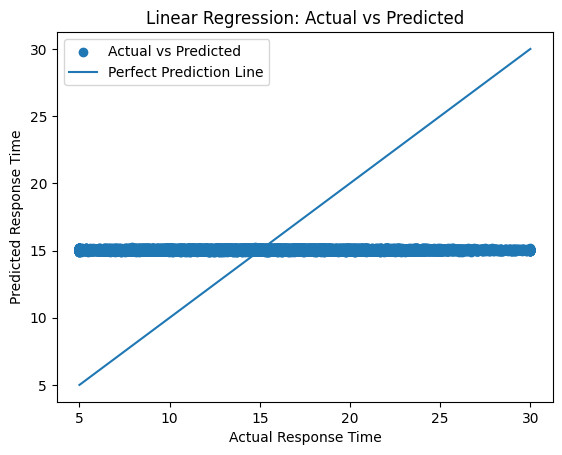

In [48]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_linear, label='Actual vs Predicted')

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    label='Perfect Prediction Line'
)

plt.xlabel('Actual Response Time')
plt.ylabel('Predicted Response Time')
plt.title('Linear Regression: Actual vs Predicted')
plt.legend()
plt.show()
#The plot shows that the Linear Regression predictions are concentrated around
#a narrow range near the average response time.
#This indicates that the model failed to capture the variation in actual response times, 
#which is also supported by the very low R² score.

In [51]:
# the third model i will use is decision tree regression 
from sklearn.tree import DecisionTreeRegressor
depth_values = [2, 3, 4, 5, 6, 7, 8, 9, 10]
dt_results = []
for depth in depth_values:
    dt_model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    dt_model.fit(X_train, y_train)
    y_pred = dt_model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    dt_results.append([depth, mae])
dt_results_df = pd.DataFrame(dt_results, columns=['Max Depth', 'MAE'])

print(dt_results_df)

   Max Depth       MAE
0          2  3.942063
1          3  3.942447
2          4  3.943085
3          5  3.945592
4          6  3.948707
5          7  3.953874
6          8  3.955447
7          9  3.965895
8         10  3.978448


In [54]:
# Create final Decision Tree model using the best max depth
dt_model = DecisionTreeRegressor(max_depth=2, random_state=42)
# Max depth 2 was selected because it gave the lowest MAE.
dt_model.fit(X_train, y_train)
y_pred_tree = dt_model.predict(X_test)

In [56]:
#evaluate the model 
MAE_tree= mean_absolute_error(y_test,y_pred_tree)
MSE_tree = mean_squared_error(y_test,y_pred_tree)
RMSE_tree = np.sqrt(MSE_tree)
R2_tree=r2_score(y_test,y_pred_tree)

#print the results
# all the results are in minutes : MAE(minutes) ,and so on on all the results 
print("Decision Tree Results:")
print("MAE:", MAE_tree)
print("MSE:", MSE_tree)
print("RMSE:", RMSE_tree)
print("R2 Score:", R2_tree)
#The model performance is weak based on the R2 score.

Decision Tree Results:
MAE: 3.9420626709169246
MSE: 23.934364487774605
RMSE: 4.892276002820631
R2 Score: -0.0004147044773170627


In [57]:
'Response_Time' in x_encoded.columns

False

In [58]:
x_encoded.select_dtypes(include='object').columns

Index([], dtype='object')

In [59]:
x_encoded.isnull().sum().sum()

np.int64(0)

In [60]:
#in this step, I created a comparison table for the three predictive models.
#the table shows the performance of each model using MAE, MSE, RMSE, and R2 Score.
#this helps me compare the models and choose the best one.
models_names = [ 'KNN Regression','Linear Regression', 'Decision Tree Regression']

mae_values = [ MAE_knn,  MAE_linear, MAE_tree]

mse_values = [MSE_knn, MSE_linear, MSE_tree]

rmse_values = [RMSE_knn,RMSE_linear, RMSE_tree]

r2_values = [R2_knn ,R2_linear, R2_tree]

# then , im gonna put all results in one DataFrame, to be more clear
results_df = pd.DataFrame({
    'Model': models_names,
    'MAE': mae_values,
    'MSE': mse_values,
    'RMSE': rmse_values,
    'R2 Score': r2_values
})
# Show the comparison table
# all the results are in minutes : MAE(minutes) ,and so on on all the results 
results_df

,Model,MAE,MSE,RMSE,R2 Score
0,KNN Regression,4.127594,26.321173,5.130416,-0.100179
1,Linear Regression,3.941750,23.930753,4.891907,-0.000264
2,Decision Tree Regression,3.942063,23.934364,4.892276,-0.000415


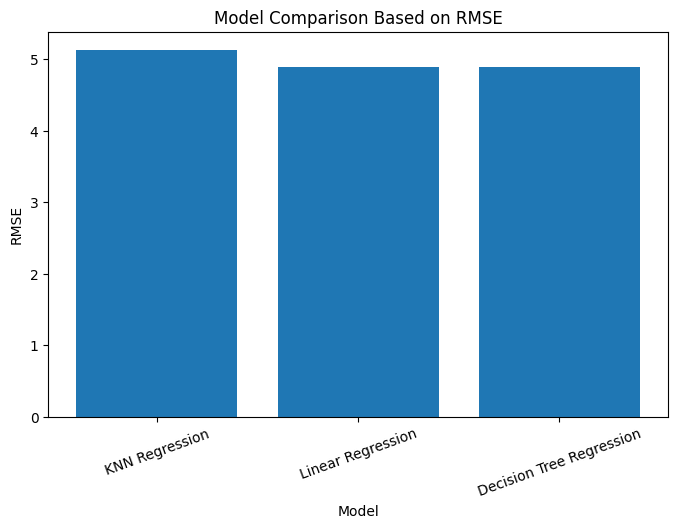

In [61]:
plt.figure(figsize=(8,5))
plt.bar(results_df['Model'], results_df['RMSE'])
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Model Comparison Based on RMSE")
plt.xticks(rotation=20)
plt.show()
#The RMSE comparison shows that the three models have very close error values. 
#This means that the models produced similar prediction performance. 
#Since lower RMSE indicates better performance,
#the model with the smallest RMSE can be considered the best, but the difference between the models is very small.

## Final Insights 
The three regression models were compared using MAE, MSE, RMSE, and R2 Score. Linear Regression achieved the best overall performance among the tested models because it had the lowest MAE and RMSE and the highest R2 Score. KNN Regression and Decision Tree Regression were also tested, but they did not outperform Linear Regression.

However, the R2 values for all models were close to zero or negative, which means the prediction performance was weak. This suggests that the available features may not explain response time strongly in this dataset.

These insights can support emergency response planning by helping decision-makers compare prediction models, estimate future response times, and improve resource allocation based on historical incident data.

## Conclusion

In this activity, predictive analytics was used to predict emergency response time using historical emergency incident data. Two feature selection techniques were applied: SelectKBest and SelectFromModel, to identify the most relevant predictors.

Three regression models were implemented: KNN Regression, Linear Regression, and Decision Tree Regression. The models were evaluated using MAE, MSE, RMSE, and R2 Score. Based on the comparison results, Linear Regression was the best model among the tested models because it achieved the lowest MAE and RMSE and the highest R2 Score.

However, the R2 values were close to zero or negative, which means the models had weak predictive performance. This suggests that the available features do not strongly explain the changes in response time. Even with limited accuracy, predictive analytics can still support emergency response planning by comparing models, estimating expected response time, and helping decision-makers improve resource allocation.